In [2]:
import os

for root, dirs, files in os.walk('/kaggle/input'):
    print(root)

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/jshanky
/kaggle/input/datasets/jshanky/zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset/images
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset
/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset/images


In [3]:
import os
import shutil
import pandas as pd

# Original dataset paths
train_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated train dataset'
test_source = '/kaggle/input/datasets/jshanky/zenodo/Zenodo/updated test dataset'

# Label files
train_excel = os.path.join(train_source, 'class_label.xlsx')
test_csv = os.path.join(test_source, 'class label.csv')

# Image folders
train_images = os.path.join(train_source, 'images')
test_images = os.path.join(test_source, 'images')

# New folders for ImageFolder
output_root = '/kaggle/working/PCOSGen-train'

train_dir = os.path.join(output_root, 'train')
test_dir = os.path.join(output_root, 'test')

# Create class folders
for directory in [
    os.path.join(train_dir, 'Appears normal'),
    os.path.join(train_dir, 'Appears abnormal'),
    os.path.join(test_dir, 'Appears normal'),
    os.path.join(test_dir, 'Appears abnormal')
]:
    os.makedirs(directory, exist_ok=True)

# Read labels
train_df = pd.read_excel(train_excel)
test_df = pd.read_csv(test_csv)

# Column we actually want
label_column = 'Class label (whether the ultrasound images appears normal or has some abnormality)'

# Function to copy images according to labels
def prepare_dataset(df, image_source, output_dir):
    copied = 0
    skipped = 0

    for _, row in df.iterrows():

        image_path = str(row['imagePath']).strip()
        label = str(row[label_column]).strip().lower()

        # Ignore Unknown / missing labels
        if label == 'unknown' or label == 'nan':
            skipped += 1
            continue

        # Determine target class
        if 'normal' in label and 'abnormal' not in label:
            class_name = 'Appears normal'
        elif 'abnormal' in label:
            class_name = 'Appears abnormal'
        else:
            skipped += 1
            continue

        # ImagePath may contain directories, so use only the filename
        image_name = os.path.basename(image_path)
        source_file = os.path.join(image_source, image_name)

        if not os.path.exists(source_file):
            skipped += 1
            continue

        destination = os.path.join(output_dir, class_name, image_name)

        shutil.copy2(source_file, destination)
        copied += 1

    return copied, skipped


# Prepare train and test
train_copied, train_skipped = prepare_dataset(
    train_df,
    train_images,
    train_dir
)

test_copied, test_skipped = prepare_dataset(
    test_df,
    test_images,
    test_dir
)

print("Dataset preparation complete!")
print(f"Train images copied : {train_copied}")
print(f"Train images skipped: {train_skipped}")
print(f"Test images copied  : {test_copied}")
print(f"Test images skipped : {test_skipped}")

Dataset preparation complete!
Train images copied : 3200
Train images skipped: 1
Test images copied  : 1468
Test images skipped : 0


In [4]:
from collections import Counter
import os

for split in ['train', 'test']:
    print(f"\n{split.upper()}")

    for class_name in ['Appears normal', 'Appears abnormal']:
        path = os.path.join(output_root, split, class_name)
        count = len(os.listdir(path))
        print(f"{class_name}: {count}")


TRAIN
Appears normal: 903
Appears abnormal: 2297

TEST
Appears normal: 416
Appears abnormal: 1052


# Random Forest

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 13.6M/13.6M [00:00<00:00, 103MB/s] 
100%|██████████| 43/43 [00:20<00:00,  2.13it/s]


Epoch [1/50] Train Loss: 0.4834 (CE: 0.5952, Dice: 0.3717), Train Acc: 0.6559 | Val Loss: 0.5060 (CE: 0.6266, Dice: 0.3854), Val Acc: 0.6354
  -> Saving best model (Val Accuracy: 0.6354)


100%|██████████| 43/43 [00:18<00:00,  2.36it/s]


Epoch [2/50] Train Loss: 0.4411 (CE: 0.5274, Dice: 0.3549), Train Acc: 0.6842 | Val Loss: 0.7071 (CE: 0.9717, Dice: 0.4424), Val Acc: 0.5563
  -> No improvement for 1/8 epochs


...

Epoch [10/50] Train Loss: 0.4014 (CE: 0.4826, Dice: 0.3202), Train Acc: 0.7272 | Val Loss: 0.4493 (CE: 0.5258, Dice: 0.3729), Val Acc: 0.6729
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.24it/s]


Epoch [11/50] Train Loss: 0.4036 (CE: 0.4865, Dice: 0.3206), Train Acc: 0.7279 | Val Loss: 0.4511 (CE: 0.5304, Dice: 0.3719), Val Acc: 0.6667
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 11. Best Val Accuracy: 0.7125

Extracting MobileNetV2 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 1280)

Random Forest Validation Accuracy: 0.6937
Random Forest Test Accuracy: 0.9040

Random Forest Test Precision: 0.9026
Random Forest Test Recall:    0.9040
Random Forest Test F1-score:  0.9029

Random Forest Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.92      0.95      0.93      1052
  Appears normal       0.86      0.80      0.82       416

        accuracy                           0.90      1468
       macro avg       0.89      0.87      0.88      1468
    weighted avg       0.90      0.90      0.90      1468



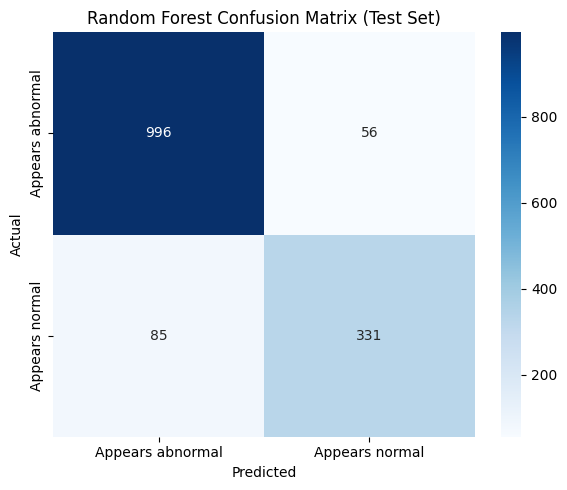


Final MobileNetV2 Test Loss: 0.4048 (CE: 0.2857, Dice: 0.5240), Final MobileNetV2 Test Accuracy: 0.9210

MobileNetV2 Test Precision (weighted): 0.9207
MobileNetV2 Test Recall (weighted):    0.9210
MobileNetV2 Test F1-score (weighted):  0.9208

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.94      0.95      0.95      1052
  Appears normal       0.87      0.85      0.86       416

        accuracy                           0.92      1468
       macro avg       0.90      0.90      0.90      1468
    weighted avg       0.92      0.92      0.92      1468



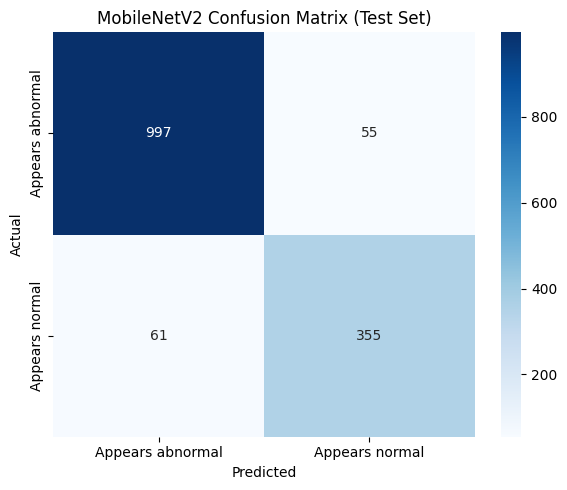

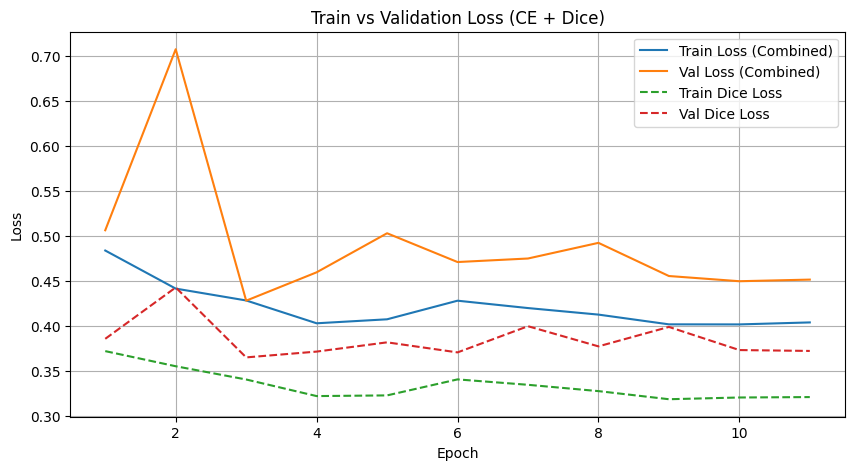

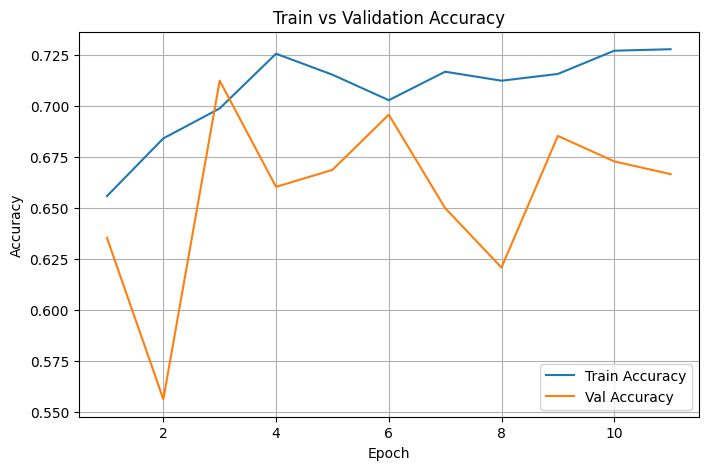


================ FINAL SUMMARY ================
Best MobileNetV2 Val Accuracy: 0.7125
MobileNetV2 Test Accuracy: 0.9210
MobileNetV2 Test Precision: 0.9207
MobileNetV2 Test Recall: 0.9210
MobileNetV2 Test F1-score: 0.9208
MobileNetV2 Test Dice Loss: 0.5240

--------------- Random Forest ----------------
Random Forest Val Accuracy: 0.6937
Random Forest Test Accuracy: 0.9040
Random Forest Test Precision: 0.9026
Random Forest Test Recall: 0.9040
Random Forest Test F1-score: 0.9029


In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size
train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [train_dataset.targets[i] for i in train_subset.indices]
class_counts = np.bincount(train_targets)
class_weights = 1. / class_counts
sample_weights = [class_weights[label] for label in train_targets]

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)

train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# Load pre-trained MobileNetV2 model
mobilenet = models.mobilenet_v2(pretrained=True)

num_classes = len(train_dataset.classes)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss (adapted for multi-class classification)
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (probs * targets_one_hot).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection + self.smooth
        ) / (
            union + self.smooth
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses = []
train_accs = []

val_losses = []
val_accs = []

train_ce_losses = []
train_dice_losses = []

val_ce_losses = []
val_dice_losses = []


# ============================================================
# MobileNetV2 Training
# ============================================================

for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )

    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )

    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# RANDOM FOREST
# MobileNetV2 feature extraction + Random Forest
# ============================================================

def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # MobileNetV2 feature extractor
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten features
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting MobileNetV2 features...")

train_features, train_labels = extract_features(
    best_mobilenet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_mobilenet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_mobilenet_model,
    test_loader
)

print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train Random Forest
# ============================================================

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight='balanced'
)

rf_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Random Forest Validation
# ============================================================

rf_val_preds = rf_model.predict(
    val_features
)

rf_val_accuracy = np.mean(
    rf_val_preds == val_labels
)

print(
    f"\nRandom Forest Validation Accuracy: "
    f"{rf_val_accuracy:.4f}"
)


# ============================================================
# Random Forest Test
# ============================================================

rf_test_preds = rf_model.predict(
    test_features
)

rf_test_accuracy = np.mean(
    rf_test_preds == test_labels
)

print(
    f"Random Forest Test Accuracy: "
    f"{rf_test_accuracy:.4f}"
)


# ============================================================
# Random Forest Metrics
# ============================================================

class_names = train_dataset.classes

rf_precision = precision_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)

rf_recall = recall_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)

rf_f1 = f1_score(
    test_labels,
    rf_test_preds,
    average='weighted'
)

print(
    f"\nRandom Forest Test Precision: "
    f"{rf_precision:.4f}"
)

print(
    f"Random Forest Test Recall:    "
    f"{rf_recall:.4f}"
)

print(
    f"Random Forest Test F1-score:  "
    f"{rf_f1:.4f}"
)


# ============================================================
# Random Forest Classification Report
# ============================================================

print(
    "\nRandom Forest Per-class report:"
)

print(
    classification_report(
        test_labels,
        rf_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Random Forest Confusion Matrix
# ============================================================

rf_cm = confusion_matrix(
    test_labels,
    rf_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Random Forest Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL MOBILENET TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)

class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)

print(
    f'\nMobileNetV2 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall (weighted):    '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# MobileNetV2 Classification Report
# ============================================================

print('\nMobileNetV2 Per-class report:')

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'MobileNetV2 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print('\n================ FINAL SUMMARY ================')

print(
    f'Best MobileNetV2 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'MobileNetV2 Test Dice Loss: '
    f'{test_dice:.4f}'
)

print('\n--------------- Random Forest ----------------')

print(
    f'Random Forest Val Accuracy: '
    f'{rf_val_accuracy:.4f}'
)

print(
    f'Random Forest Test Accuracy: '
    f'{rf_test_accuracy:.4f}'
)

print(
    f'Random Forest Test Precision: '
    f'{rf_precision:.4f}'
)

print(
    f'Random Forest Test Recall: '
    f'{rf_recall:.4f}'
)

print(
    f'Random Forest Test F1-score: '
    f'{rf_f1:.4f}'
)

# KNN

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:19<00:00,  2.24it/s]


Epoch [1/50] Train Loss: 0.4796 (CE: 0.5897, Dice: 0.3695), Train Acc: 0.6732 | Val Loss: 0.4765 (CE: 0.5555, Dice: 0.3975), Val Acc: 0.5958
  -> Saving best model (Val Accuracy: 0.5958)


100%|██████████| 43/43 [00:19<00:00,  2.23it/s]


Epoch [2/50] Train Loss: 0.4342 (CE: 0.5197, Dice: 0.3487), Train Acc: 0.6849 | Val Loss: 0.4912 (CE: 0.5858, Dice: 0.3965), Val Acc: 0.5646
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.24it/s]


...

Epoch [25/50] Train Loss: 0.3515 (CE: 0.4237, Dice: 0.2793), Train Acc: 0.7662 | Val Loss: 0.4955 (CE: 0.6281, Dice: 0.3629), Val Acc: 0.6937
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:19<00:00,  2.19it/s]


Epoch [26/50] Train Loss: 0.3739 (CE: 0.4570, Dice: 0.2909), Train Acc: 0.7515 | Val Loss: 0.5508 (CE: 0.6873, Dice: 0.4143), Val Acc: 0.5729
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 26. Best Val Accuracy: 0.7521

Extracting MobileNetV2 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 1280)

KNN Validation Accuracy: 0.6875
KNN Test Accuracy: 0.8951

KNN Test Precision: 0.8940
KNN Test Recall:    0.8951
KNN Test F1-score:  0.8921

KNN Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.90      0.96      0.93      1052
  Appears normal       0.88      0.73      0.80       416

        accuracy                           0.90      1468
       macro avg       0.89      0.85      0.86      1468
    weighted avg       0.89      0.90      0.89      1468



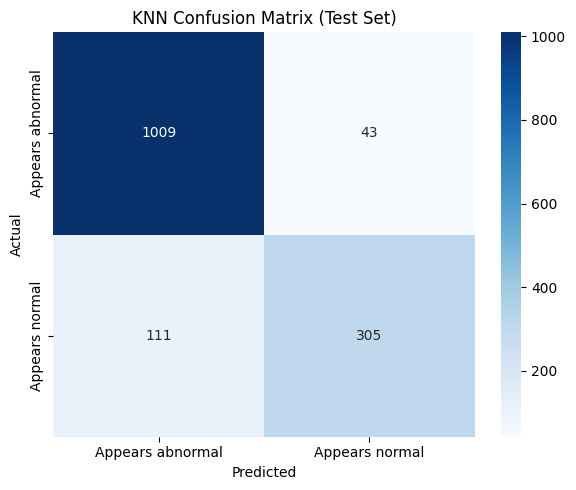


Final MobileNetV2 Test Loss: 0.4501 (CE: 0.3672, Dice: 0.5329), Final MobileNetV2 Test Accuracy: 0.8815

MobileNetV2 Test Precision (weighted): 0.8853
MobileNetV2 Test Recall (weighted):    0.8815
MobileNetV2 Test F1-score (weighted):  0.8742

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.87      0.98      0.92      1052
  Appears normal       0.92      0.64      0.75       416

        accuracy                           0.88      1468
       macro avg       0.89      0.81      0.84      1468
    weighted avg       0.89      0.88      0.87      1468



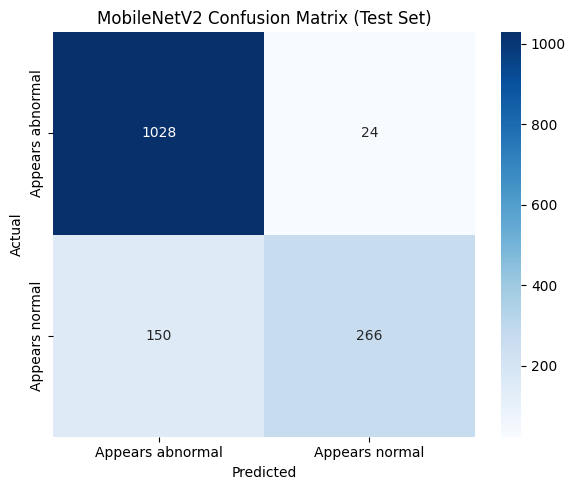

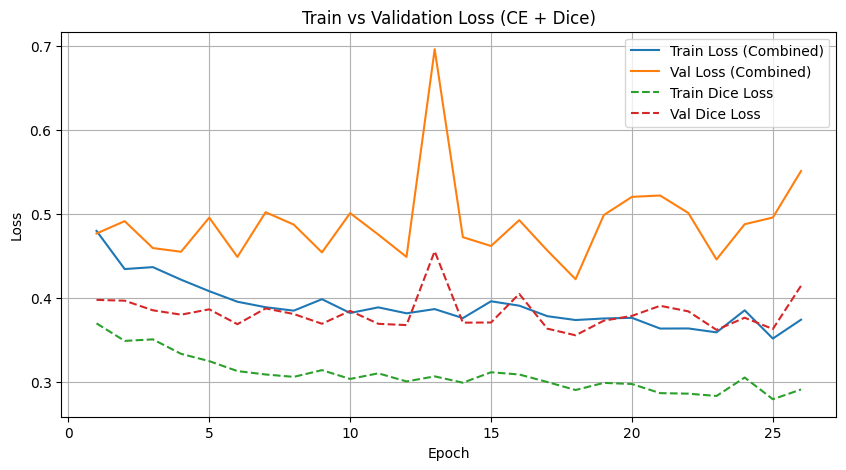

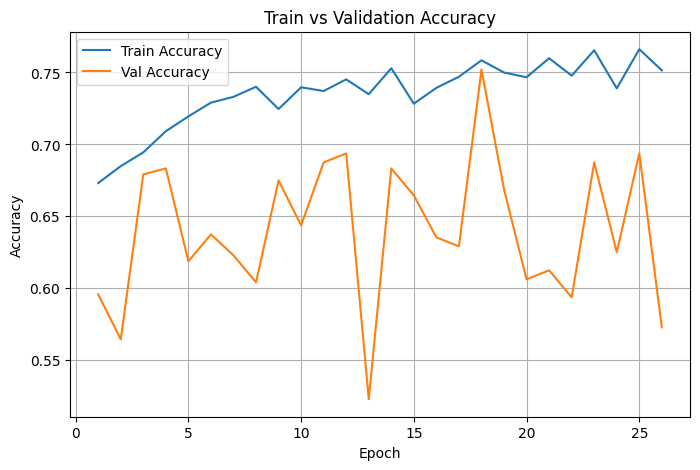


================ FINAL SUMMARY ================
Best MobileNetV2 Val Accuracy: 0.7521
MobileNetV2 Test Accuracy: 0.8815
MobileNetV2 Test Precision: 0.8853
MobileNetV2 Test Recall: 0.8815
MobileNetV2 Test F1-score: 0.8742
MobileNetV2 Test Dice Loss: 0.5329

---------------- KNN ----------------
KNN Validation Accuracy: 0.6875
KNN Test Accuracy: 0.8951
KNN Test Precision: 0.8940
KNN Test Recall: 0.8951
KNN Test F1-score: 0.8921


In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# Load pre-trained MobileNetV2 model
mobilenet = models.mobilenet_v2(pretrained=True)

num_classes = len(train_dataset.classes)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection + self.smooth
        ) / (
            union + self.smooth
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []

val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []

val_ce_losses, val_dice_losses = [], []


# ============================================================
# MobileNetV2 Training
# ============================================================

for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# KNN
# MobileNetV2 Feature Extraction + KNN
# ============================================================

def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract features before MobileNet classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting MobileNetV2 features...")


train_features, train_labels = extract_features(
    best_mobilenet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_mobilenet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_mobilenet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train KNN
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    train_features,
    train_labels
)


# ============================================================
# KNN Validation
# ============================================================

knn_val_preds = knn_model.predict(
    val_features
)

knn_val_accuracy = np.mean(
    knn_val_preds == val_labels
)

print(
    f"\nKNN Validation Accuracy: "
    f"{knn_val_accuracy:.4f}"
)


# ============================================================
# KNN Test
# ============================================================

knn_test_preds = knn_model.predict(
    test_features
)

knn_test_accuracy = np.mean(
    knn_test_preds == test_labels
)

print(
    f"KNN Test Accuracy: "
    f"{knn_test_accuracy:.4f}"
)


# ============================================================
# KNN Metrics
# ============================================================

class_names = train_dataset.classes


knn_precision = precision_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)

knn_recall = recall_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)

knn_f1 = f1_score(
    test_labels,
    knn_test_preds,
    average='weighted'
)


print(
    f"\nKNN Test Precision: "
    f"{knn_precision:.4f}"
)

print(
    f"KNN Test Recall:    "
    f"{knn_recall:.4f}"
)

print(
    f"KNN Test F1-score:  "
    f"{knn_f1:.4f}"
)


# ============================================================
# KNN Classification Report
# ============================================================

print(
    "\nKNN Per-class report:"
)

print(
    classification_report(
        test_labels,
        knn_test_preds,
        target_names=class_names
    )
)


# ============================================================
# KNN Confusion Matrix
# ============================================================

knn_cm = confusion_matrix(
    test_labels,
    knn_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    knn_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'KNN Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL MOBILENETV2 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)

class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nMobileNetV2 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall (weighted):    '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# MobileNetV2 Classification Report
# ============================================================

print(
    '\nMobileNetV2 Per-class report:'
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'MobileNetV2 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)

print(
    f'Best MobileNetV2 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'MobileNetV2 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n---------------- KNN ----------------'
)

print(
    f'KNN Validation Accuracy: '
    f'{knn_val_accuracy:.4f}'
)

print(
    f'KNN Test Accuracy: '
    f'{knn_test_accuracy:.4f}'
)

print(
    f'KNN Test Precision: '
    f'{knn_precision:.4f}'
)

print(
    f'KNN Test Recall: '
    f'{knn_recall:.4f}'
)

print(
    f'KNN Test F1-score: '
    f'{knn_f1:.4f}'
)

# Naive Bayes

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:18<00:00,  2.27it/s]


Epoch [1/50] Train Loss: 0.4597 (CE: 0.5664, Dice: 0.3529), Train Acc: 0.6728 | Val Loss: 0.6026 (CE: 0.7827, Dice: 0.4224), Val Acc: 0.6271
  -> Saving best model (Val Accuracy: 0.6271)


100%|██████████| 43/43 [00:18<00:00,  2.26it/s]


Epoch [2/50] Train Loss: 0.4236 (CE: 0.5054, Dice: 0.3418), Train Acc: 0.6923 | Val Loss: 0.4692 (CE: 0.5672, Dice: 0.3711), Val Acc: 0.6875
  -> Saving best model (Val Accuracy: 0.6875)


100%|██████████| 43/43 [00:18<00:00,  2.30it/s]


...

Epoch [18/50] Train Loss: 0.3813 (CE: 0.4601, Dice: 0.3025), Train Acc: 0.7397 | Val Loss: 0.4452 (CE: 0.5405, Dice: 0.3499), Val Acc: 0.6771
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.32it/s]


Epoch [19/50] Train Loss: 0.3795 (CE: 0.4554, Dice: 0.3035), Train Acc: 0.7526 | Val Loss: 0.4772 (CE: 0.6103, Dice: 0.3442), Val Acc: 0.6896
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 19. Best Val Accuracy: 0.7125

Extracting MobileNetV2 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 1280)

Naive Bayes Validation Accuracy: 0.6083
Naive Bayes Test Accuracy: 0.9142

Naive Bayes Test Precision: 0.9185
Naive Bayes Test Recall:    0.9142
Naive Bayes Test F1-score:  0.9154

Naive Bayes Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.96      0.92      0.94      1052
  Appears normal       0.82      0.90      0.86       416

        accuracy                           0.91      1468
       macro avg       0.89      0.91      0.90      1468
    weighted avg       0.92      0.91      0.92      1468



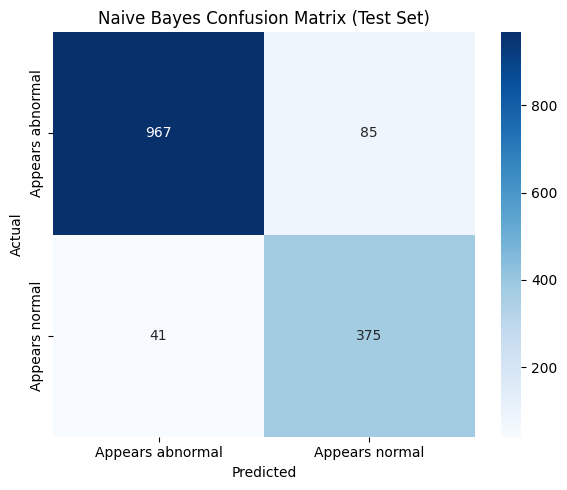


Final MobileNetV2 Test Loss: 0.4302 (CE: 0.3437, Dice: 0.5168), Final MobileNetV2 Test Accuracy: 0.9203

MobileNetV2 Test Precision (weighted): 0.9197
MobileNetV2 Test Recall (weighted):    0.9203
MobileNetV2 Test F1-score (weighted):  0.9188

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.93      0.97      0.95      1052
  Appears normal       0.91      0.80      0.85       416

        accuracy                           0.92      1468
       macro avg       0.92      0.88      0.90      1468
    weighted avg       0.92      0.92      0.92      1468



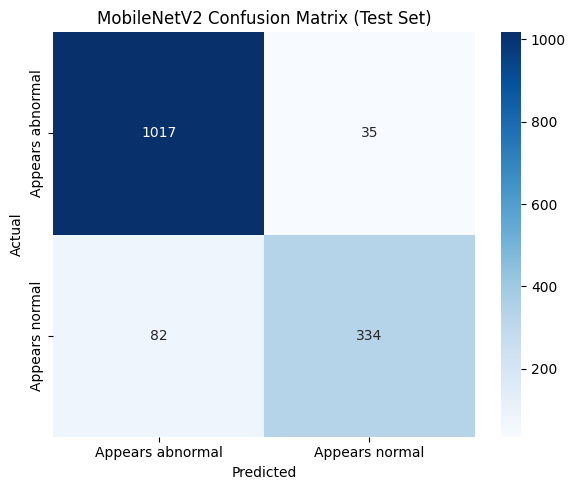

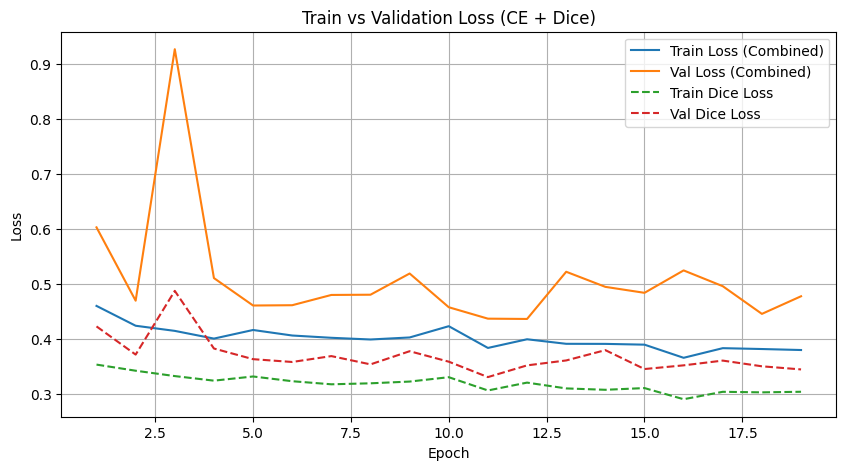

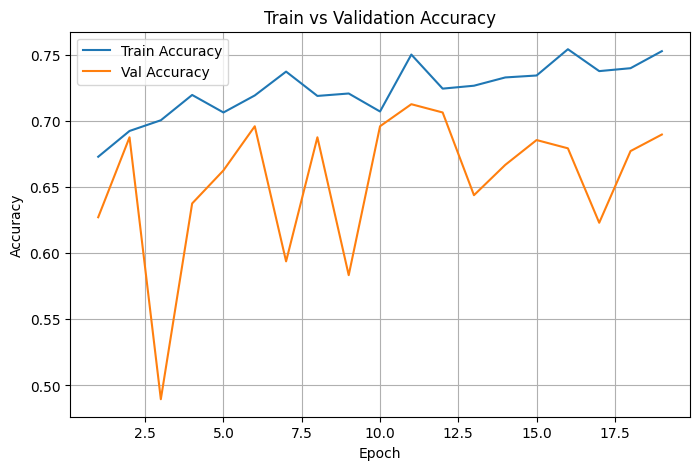


================ FINAL SUMMARY ================
Best MobileNetV2 Val Accuracy: 0.7125
MobileNetV2 Test Accuracy: 0.9203
MobileNetV2 Test Precision: 0.9197
MobileNetV2 Test Recall: 0.9203
MobileNetV2 Test F1-score: 0.9188
MobileNetV2 Test Dice Loss: 0.5168

---------------- Naive Bayes ----------------
Naive Bayes Validation Accuracy: 0.6083
Naive Bayes Test Accuracy: 0.9142
Naive Bayes Test Precision: 0.9185
Naive Bayes Test Recall: 0.9142
Naive Bayes Test F1-score: 0.9154


In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import GaussianNB
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# Load pre-trained MobileNetV2 model
mobilenet = models.mobilenet_v2(pretrained=True)

num_classes = len(train_dataset.classes)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection + self.smooth
        ) / (
            union + self.smooth
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []

val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []

val_ce_losses, val_dice_losses = [], []


# ============================================================
# MobileNetV2 Training
# ============================================================

for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# NAIVE BAYES
# MobileNetV2 Feature Extraction + Gaussian Naive Bayes
# ============================================================

def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract features before MobileNet classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting MobileNetV2 features...")


train_features, train_labels = extract_features(
    best_mobilenet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_mobilenet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_mobilenet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train Naive Bayes
# ============================================================

nb_model = GaussianNB()

nb_model.fit(
    train_features,
    train_labels
)


# ============================================================
# Naive Bayes Validation
# ============================================================

nb_val_preds = nb_model.predict(
    val_features
)

nb_val_accuracy = np.mean(
    nb_val_preds == val_labels
)

print(
    f"\nNaive Bayes Validation Accuracy: "
    f"{nb_val_accuracy:.4f}"
)


# ============================================================
# Naive Bayes Test
# ============================================================

nb_test_preds = nb_model.predict(
    test_features
)

nb_test_accuracy = np.mean(
    nb_test_preds == test_labels
)

print(
    f"Naive Bayes Test Accuracy: "
    f"{nb_test_accuracy:.4f}"
)


# ============================================================
# Naive Bayes Metrics
# ============================================================

class_names = train_dataset.classes


nb_precision = precision_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)

nb_recall = recall_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)

nb_f1 = f1_score(
    test_labels,
    nb_test_preds,
    average='weighted'
)


print(
    f"\nNaive Bayes Test Precision: "
    f"{nb_precision:.4f}"
)

print(
    f"Naive Bayes Test Recall:    "
    f"{nb_recall:.4f}"
)

print(
    f"Naive Bayes Test F1-score:  "
    f"{nb_f1:.4f}"
)


# ============================================================
# Naive Bayes Classification Report
# ============================================================

print(
    "\nNaive Bayes Per-class report:"
)

print(
    classification_report(
        test_labels,
        nb_test_preds,
        target_names=class_names
    )
)


# ============================================================
# Naive Bayes Confusion Matrix
# ============================================================

nb_cm = confusion_matrix(
    test_labels,
    nb_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    nb_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'Naive Bayes Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL MOBILENETV2 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)

class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nMobileNetV2 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall (weighted):    '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# MobileNetV2 Classification Report
# ============================================================

print(
    '\nMobileNetV2 Per-class report:'
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'MobileNetV2 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)

print(
    f'Best MobileNetV2 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'MobileNetV2 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n---------------- Naive Bayes ----------------'
)

print(
    f'Naive Bayes Validation Accuracy: '
    f'{nb_val_accuracy:.4f}'
)

print(
    f'Naive Bayes Test Accuracy: '
    f'{nb_test_accuracy:.4f}'
)

print(
    f'Naive Bayes Test Precision: '
    f'{nb_precision:.4f}'
)

print(
    f'Naive Bayes Test Recall: '
    f'{nb_recall:.4f}'
)

print(
    f'Naive Bayes Test F1-score: '
    f'{nb_f1:.4f}'
)

# Adaboost

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 43/43 [00:18<00:00,  2.33it/s]


Epoch [1/50] Train Loss: 0.4863 (CE: 0.6083, Dice: 0.3643), Train Acc: 0.6724 | Val Loss: 0.5107 (CE: 0.6183, Dice: 0.4030), Val Acc: 0.6396
  -> Saving best model (Val Accuracy: 0.6396)


100%|██████████| 43/43 [00:18<00:00,  2.32it/s]


Epoch [2/50] Train Loss: 0.4271 (CE: 0.5187, Dice: 0.3355), Train Acc: 0.6985 | Val Loss: 0.4956 (CE: 0.6090, Dice: 0.3821), Val Acc: 0.5938
  -> No improvement for 1/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.34it/s]


...

Epoch [22/50] Train Loss: 0.3684 (CE: 0.4446, Dice: 0.2921), Train Acc: 0.7551 | Val Loss: 0.4960 (CE: 0.6219, Dice: 0.3701), Val Acc: 0.6708
  -> No improvement for 7/8 epochs


100%|██████████| 43/43 [00:18<00:00,  2.35it/s]


Epoch [23/50] Train Loss: 0.3885 (CE: 0.4711, Dice: 0.3059), Train Acc: 0.7346 | Val Loss: 0.4654 (CE: 0.5590, Dice: 0.3717), Val Acc: 0.6521
  -> No improvement for 8/8 epochs

Early stopping triggered at epoch 23. Best Val Accuracy: 0.7542

Extracting MobileNetV2 features...


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Feature shape: (2720, 1280)

AdaBoost Validation Accuracy: 0.6500
AdaBoost Test Accuracy: 0.9312

AdaBoost Test Precision: 0.9312
AdaBoost Test Recall:    0.9312
AdaBoost Test F1-score:  0.9312

AdaBoost Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.95      0.95      0.95      1052
  Appears normal       0.88      0.88      0.88       416

        accuracy                           0.93      1468
       macro avg       0.92      0.92      0.92      1468
    weighted avg       0.93      0.93      0.93      1468



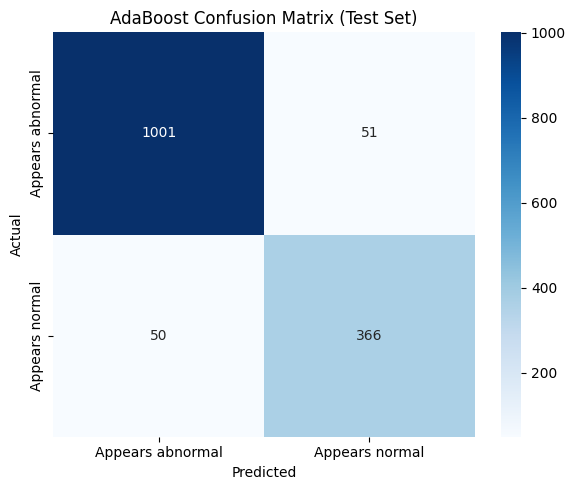


Final MobileNetV2 Test Loss: 0.5470 (CE: 0.5615, Dice: 0.5325), Final MobileNetV2 Test Accuracy: 0.8815

MobileNetV2 Test Precision (weighted): 0.8869
MobileNetV2 Test Recall (weighted):    0.8815
MobileNetV2 Test F1-score (weighted):  0.8736

MobileNetV2 Per-class report:
                  precision    recall  f1-score   support

Appears abnormal       0.87      0.98      0.92      1052
  Appears normal       0.93      0.63      0.75       416

        accuracy                           0.88      1468
       macro avg       0.90      0.81      0.84      1468
    weighted avg       0.89      0.88      0.87      1468



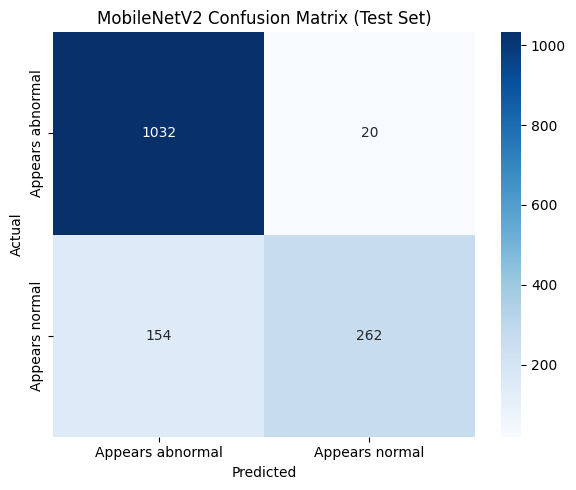

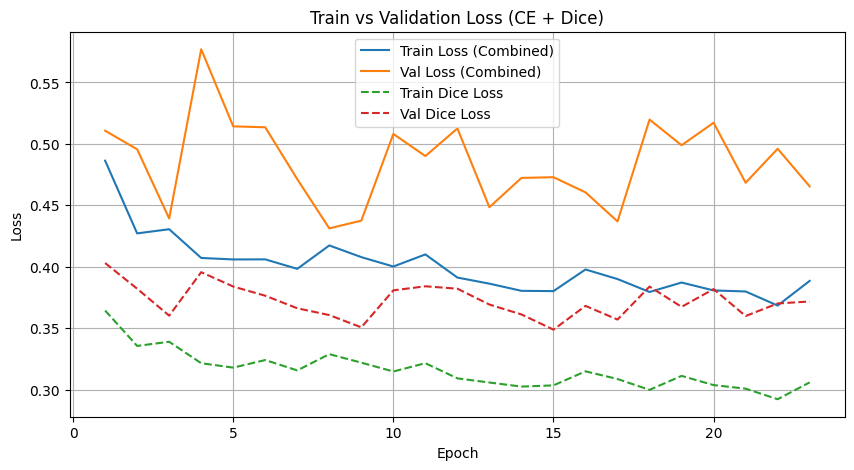

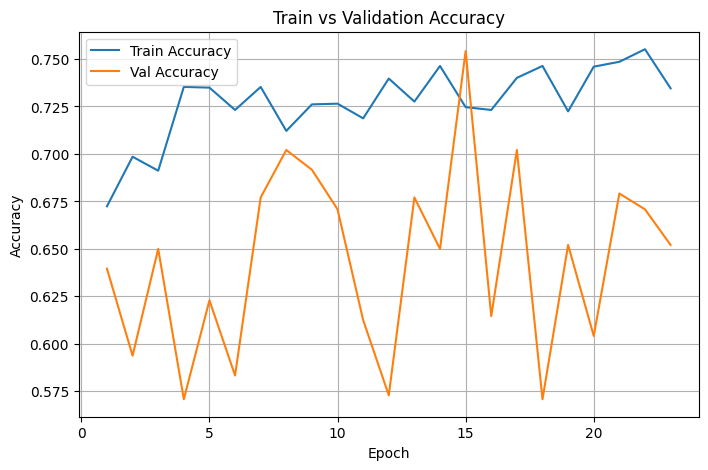


================ FINAL SUMMARY ================
Best MobileNetV2 Val Accuracy: 0.7542
MobileNetV2 Test Accuracy: 0.8815
MobileNetV2 Test Precision: 0.8869
MobileNetV2 Test Recall: 0.8815
MobileNetV2 Test F1-score: 0.8736
MobileNetV2 Test Dice Loss: 0.5325

---------------- AdaBoost ----------------
AdaBoost Validation Accuracy: 0.6500
AdaBoost Test Accuracy: 0.9312
AdaBoost Test Precision: 0.9312
AdaBoost Test Recall: 0.9312
AdaBoost Test F1-score: 0.9312


In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, random_split
from torchvision import datasets, transforms, models
from tqdm import tqdm
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.ensemble import AdaBoostClassifier
import seaborn as sns


# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Paths to train and test datasets
train_dir = '/kaggle/working/PCOSGen-train/train'
test_dir = '/kaggle/working/PCOSGen-train/test'


# Image transformations
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


# Datasets
train_dataset = datasets.ImageFolder(train_dir, transform=train_transform)
test_dataset = datasets.ImageFolder(test_dir, transform=test_transform)


# Split train_dataset into train_subset + val_subset (85/15)
val_size = int(0.15 * len(train_dataset))
train_size = len(train_dataset) - val_size

train_subset, val_subset = random_split(
    train_dataset,
    [train_size, val_size]
)


# Count the number of samples per class (within train_subset)
train_targets = [
    train_dataset.targets[i]
    for i in train_subset.indices
]

class_counts = np.bincount(train_targets)

class_weights = 1. / class_counts

sample_weights = [
    class_weights[label]
    for label in train_targets
]


sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(train_subset),
    replacement=True
)


train_loader = DataLoader(
    train_subset,
    batch_size=64,
    sampler=sampler
)

val_loader = DataLoader(
    val_subset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


# Load pre-trained MobileNetV2 model
mobilenet = models.mobilenet_v2(pretrained=True)

num_classes = len(train_dataset.classes)

mobilenet.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

mobilenet = mobilenet.to(device)


# ============================================================
# Dice Loss
# ============================================================

class DiceLoss(nn.Module):

    def __init__(self, num_classes, smooth=1e-6):
        super().__init__()

        self.num_classes = num_classes
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = F.softmax(logits, dim=1)

        targets_one_hot = F.one_hot(
            targets,
            num_classes=self.num_classes
        ).float()

        intersection = (
            probs * targets_one_hot
        ).sum(dim=0)

        union = (
            probs.sum(dim=0)
            + targets_one_hot.sum(dim=0)
        )

        dice_score = (
            2. * intersection + self.smooth
        ) / (
            union + self.smooth
        )

        dice_loss = 1. - dice_score.mean()

        return dice_loss


# ============================================================
# Combined CrossEntropy + Dice Loss
# ============================================================

class CombinedLoss(nn.Module):

    def __init__(
        self,
        num_classes,
        ce_weight=0.5,
        dice_weight=0.5
    ):
        super().__init__()

        self.ce_loss = nn.CrossEntropyLoss()

        self.dice_loss = DiceLoss(num_classes)

        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits, targets):

        ce = self.ce_loss(logits, targets)

        dice = self.dice_loss(logits, targets)

        total = (
            self.ce_weight * ce
            + self.dice_weight * dice
        )

        return total, ce, dice


criterion = CombinedLoss(
    num_classes=num_classes,
    ce_weight=0.5,
    dice_weight=0.5
)

optimizer = optim.Adam(
    mobilenet.parameters(),
    lr=0.001
)


# ============================================================
# Function to evaluate the model
# ============================================================

def evaluate_model(model, loader):

    model.eval()

    correct = 0
    total = 0

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss, ce, dice = criterion(
                outputs,
                labels
            )

            running_loss += loss.item()
            running_ce += ce.item()
            running_dice += dice.item()

            _, predicted = torch.max(
                outputs,
                1
            )

            total += labels.size(0)

            correct += (
                predicted == labels
            ).sum().item()

    accuracy = correct / total

    n = len(loader)

    return (
        accuracy,
        running_loss / n,
        running_ce / n,
        running_dice / n
    )


# ============================================================
# Get predictions
# ============================================================

def get_predictions(model, loader):

    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            _, predicted = torch.max(
                outputs,
                1
            )

            all_preds.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    return all_labels, all_preds


# ============================================================
# Early stopping setup
# ============================================================

best_accuracy = 0.0

best_model_path = "Mobilenet_1410=.pkl"

patience = 8

epochs_no_improve = 0

max_epochs = 50


train_losses, train_accs = [], []

val_losses, val_accs = [], []

train_ce_losses, train_dice_losses = [], []

val_ce_losses, val_dice_losses = [], []


# ============================================================
# MobileNetV2 Training
# ============================================================

for epoch in range(max_epochs):

    mobilenet.train()

    running_loss = 0.0
    running_ce = 0.0
    running_dice = 0.0

    correct_train = 0
    total_train = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = mobilenet(images)

        loss, ce, dice = criterion(
            outputs,
            labels
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item()
        running_ce += ce.item()
        running_dice += dice.item()

        _, predicted = torch.max(
            outputs,
            1
        )

        total_train += labels.size(0)

        correct_train += (
            predicted == labels
        ).sum().item()

    train_accuracy = (
        correct_train / total_train
    )

    n_batches = len(train_loader)

    train_loss = (
        running_loss / n_batches
    )

    train_ce = (
        running_ce / n_batches
    )

    train_dice = (
        running_dice / n_batches
    )

    val_accuracy, val_loss, val_ce, val_dice = evaluate_model(
        mobilenet,
        val_loader
    )

    train_losses.append(train_loss)
    train_accs.append(train_accuracy)

    val_losses.append(val_loss)
    val_accs.append(val_accuracy)

    train_ce_losses.append(train_ce)
    train_dice_losses.append(train_dice)

    val_ce_losses.append(val_ce)
    val_dice_losses.append(val_dice)

    print(
        f'Epoch [{epoch+1}/{max_epochs}] '
        f'Train Loss: {train_loss:.4f} '
        f'(CE: {train_ce:.4f}, Dice: {train_dice:.4f}), '
        f'Train Acc: {train_accuracy:.4f} | '
        f'Val Loss: {val_loss:.4f} '
        f'(CE: {val_ce:.4f}, Dice: {val_dice:.4f}), '
        f'Val Acc: {val_accuracy:.4f}'
    )


    # Early stopping logic
    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy

        epochs_no_improve = 0

        print(
            f'  -> Saving best model '
            f'(Val Accuracy: {best_accuracy:.4f})'
        )

        torch.save(
            mobilenet.state_dict(),
            best_model_path
        )

    else:

        epochs_no_improve += 1

        print(
            f'  -> No improvement for '
            f'{epochs_no_improve}/{patience} epochs'
        )


    if epochs_no_improve >= patience:

        print(
            f'\nEarly stopping triggered at epoch '
            f'{epoch+1}. Best Val Accuracy: '
            f'{best_accuracy:.4f}'
        )

        break


# ============================================================
# Load the best MobileNetV2 model
# ============================================================

best_mobilenet_model = models.mobilenet_v2(
    pretrained=False
)

best_mobilenet_model.classifier[1] = nn.Linear(
    mobilenet.classifier[1].in_features,
    num_classes
)

best_mobilenet_model = best_mobilenet_model.to(device)

best_mobilenet_model.load_state_dict(
    torch.load(best_model_path)
)


# ============================================================
# ADABOOST
# MobileNetV2 Feature Extraction + AdaBoost
# ============================================================

def extract_features(model, loader):

    model.eval()

    features = []
    labels_list = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            # Extract features before MobileNet classifier
            x = model.features(images)

            # Global Average Pooling
            x = F.adaptive_avg_pool2d(
                x,
                (1, 1)
            )

            # Flatten
            x = torch.flatten(
                x,
                1
            )

            features.extend(
                x.cpu().numpy()
            )

            labels_list.extend(
                labels.numpy()
            )

    return (
        np.array(features),
        np.array(labels_list)
    )


print("\nExtracting MobileNetV2 features...")


train_features, train_labels = extract_features(
    best_mobilenet_model,
    train_loader
)

val_features, val_labels = extract_features(
    best_mobilenet_model,
    val_loader
)

test_features, test_labels = extract_features(
    best_mobilenet_model,
    test_loader
)


print(
    "Feature shape:",
    train_features.shape
)


# ============================================================
# Train AdaBoost
# ============================================================

adaboost_model = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

adaboost_model.fit(
    train_features,
    train_labels
)


# ============================================================
# AdaBoost Validation
# ============================================================

adaboost_val_preds = adaboost_model.predict(
    val_features
)

adaboost_val_accuracy = np.mean(
    adaboost_val_preds == val_labels
)

print(
    f"\nAdaBoost Validation Accuracy: "
    f"{adaboost_val_accuracy:.4f}"
)


# ============================================================
# AdaBoost Test
# ============================================================

adaboost_test_preds = adaboost_model.predict(
    test_features
)

adaboost_test_accuracy = np.mean(
    adaboost_test_preds == test_labels
)

print(
    f"AdaBoost Test Accuracy: "
    f"{adaboost_test_accuracy:.4f}"
)


# ============================================================
# AdaBoost Metrics
# ============================================================

class_names = train_dataset.classes


adaboost_precision = precision_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)

adaboost_recall = recall_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)

adaboost_f1 = f1_score(
    test_labels,
    adaboost_test_preds,
    average='weighted'
)


print(
    f"\nAdaBoost Test Precision: "
    f"{adaboost_precision:.4f}"
)

print(
    f"AdaBoost Test Recall:    "
    f"{adaboost_recall:.4f}"
)

print(
    f"AdaBoost Test F1-score:  "
    f"{adaboost_f1:.4f}"
)


# ============================================================
# AdaBoost Classification Report
# ============================================================

print(
    "\nAdaBoost Per-class report:"
)

print(
    classification_report(
        test_labels,
        adaboost_test_preds,
        target_names=class_names
    )
)


# ============================================================
# AdaBoost Confusion Matrix
# ============================================================

adaboost_cm = confusion_matrix(
    test_labels,
    adaboost_test_preds
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    adaboost_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'AdaBoost Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# ORIGINAL MOBILENETV2 TEST EVALUATION
# ============================================================

test_accuracy, test_loss, test_ce, test_dice = evaluate_model(
    best_mobilenet_model,
    test_loader
)

print(
    f'\nFinal MobileNetV2 Test Loss: '
    f'{test_loss:.4f} '
    f'(CE: {test_ce:.4f}, Dice: {test_dice:.4f}), '
    f'Final MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)


# ============================================================
# MobileNetV2 Test Metrics
# ============================================================

true_labels, pred_labels = get_predictions(
    best_mobilenet_model,
    test_loader
)

class_names = train_dataset.classes


precision = precision_score(
    true_labels,
    pred_labels,
    average='weighted'
)

recall = recall_score(
    true_labels,
    pred_labels,
    average='weighted'
)

f1 = f1_score(
    true_labels,
    pred_labels,
    average='weighted'
)


print(
    f'\nMobileNetV2 Test Precision (weighted): '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall (weighted):    '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score (weighted):  '
    f'{f1:.4f}'
)


# ============================================================
# MobileNetV2 Classification Report
# ============================================================

print(
    '\nMobileNetV2 Per-class report:'
)

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=class_names
    )
)


# ============================================================
# MobileNetV2 Confusion Matrix
# ============================================================

cm = confusion_matrix(
    true_labels,
    pred_labels
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    'MobileNetV2 Confusion Matrix (Test Set)'
)

plt.tight_layout()

plt.show()


# ============================================================
# Plot Train vs Val Loss
# ============================================================

epochs_range = range(
    1,
    len(train_losses) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs_range,
    train_losses,
    label='Train Loss (Combined)'
)

plt.plot(
    epochs_range,
    val_losses,
    label='Val Loss (Combined)'
)

plt.plot(
    epochs_range,
    train_dice_losses,
    '--',
    label='Train Dice Loss'
)

plt.plot(
    epochs_range,
    val_dice_losses,
    '--',
    label='Val Dice Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.title(
    'Train vs Validation Loss (CE + Dice)'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# Plot Train vs Val Accuracy
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    train_accs,
    label='Train Accuracy'
)

plt.plot(
    epochs_range,
    val_accs,
    label='Val Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.title(
    'Train vs Validation Accuracy'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# FINAL SUMMARY
# ============================================================

print(
    '\n================ FINAL SUMMARY ================'
)

print(
    f'Best MobileNetV2 Val Accuracy: '
    f'{best_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Accuracy: '
    f'{test_accuracy:.4f}'
)

print(
    f'MobileNetV2 Test Precision: '
    f'{precision:.4f}'
)

print(
    f'MobileNetV2 Test Recall: '
    f'{recall:.4f}'
)

print(
    f'MobileNetV2 Test F1-score: '
    f'{f1:.4f}'
)

print(
    f'MobileNetV2 Test Dice Loss: '
    f'{test_dice:.4f}'
)


print(
    '\n---------------- AdaBoost ----------------'
)

print(
    f'AdaBoost Validation Accuracy: '
    f'{adaboost_val_accuracy:.4f}'
)

print(
    f'AdaBoost Test Accuracy: '
    f'{adaboost_test_accuracy:.4f}'
)

print(
    f'AdaBoost Test Precision: '
    f'{adaboost_precision:.4f}'
)

print(
    f'AdaBoost Test Recall: '
    f'{adaboost_recall:.4f}'
)

print(
    f'AdaBoost Test F1-score: '
    f'{adaboost_f1:.4f}'
)